# Phase 4: Generative AI & LLM Engineering
## Notebook 07: Multi-Agent Systems & Orchestration Patterns

### Overview
Single-agent architectures (like pure ReAct) struggle when tasks grow beyond a single specialty or exceed short-term memory limits. When a single agent attempts to simultaneously plan, write software, critique its own code, and debug, it experiences cognitive drift and self-confirmation bias.

**Multi-Agent Systems (MAS)** partition complex software and engineering objectives across a team of specialized autonomous agents:
1. **Separation of Concerns**: Each agent operates with a focused system prompt, specific tools, and bounded persona (e.g., Planner, Researcher, Coder, Critic).
2. **Adversarial Critique & Verification**: By separating code generation from code review into independent agents, confirmation bias is eradicated.
3. **Graph-Based Execution**: Modern enterprise agent systems represent agent interactions as **Stateful Directed Graphs** (e.g., LangGraph), replacing chaotic open-ended chatter with deterministic transition edges and conditional routing.

### System Architecture: The Hierarchical Supervisor Pattern
```
                                   [User Objective]
                                          |
                                          v
                         +---------------------------------+
                         |        Supervisor Agent         | <----------------+
                         |  - Inspects Global State Graph  |                  |
                         |  - Dispatches to Next Specialist|                  |
                         +---------------------------------+                  |
                               /          |          \                        |
                              /           |           \                       |
                             v            v            v                      |
                 +---------------+ +---------------+ +---------------+        |
                 |  Researcher   | |     Coder     | |    Critic     |        |
                 |  - Gathers Doc| | - Implements  | | - Static Tests|        |
                 |  - Specs & KB | |   Algorithm   | | - Code Review |        |
                 +---------------+ +---------------+ +---------------+        |
                             \            |            /                      |
                              \           |           /                       |
                               v          v          v                        |
                         +---------------------------------+                  |
                         |       Shared Graph State        | -----------------+
                         |  - Messages & Task History      |
                         |  - Code Artifacts & Diagnostics |
                         |  - Review Sign-off Status       |
                         +---------------------------------+
                                          |
                               (Critic Approval Signed)
                                          |
                                          v
                                   [Final Delivery]
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **Stateful Graph Execution**: Model multi-agent collaboration as a directed state machine $\mathcal{G} = (V, E)$ with explicit reducer functions.
- **Supervisor Orchestration**: Architect a central routing controller that dynamically delegates tasks to Researcher, Coder, and Critic agents.
- **Iterative Refinement Cycles**: Establish an automated feedback loop where Critic rejections route back to the Coder for error resolution.
- **LangGraph Integration**: Build, compile, and execute production agent graphs using the official `langgraph` framework.
- **Human-in-the-Loop Breakpoints**: Implement state interruption gates that halt execution before dangerous or irreversible actions until human sign-off is granted.


In [1]:
# Environment Setup & Dependency Verification
import sys
import os
import operator
import time
from typing import Dict, List, Tuple, Optional, Any, Annotated, TypedDict
from dataclasses import dataclass, field

import numpy as np
import matplotlib.pyplot as plt
import langgraph
from langgraph.graph import StateGraph, END

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"LangGraph StateGraph: Available (Ready)")


=== Environment Verification ===
Python Platform:     3.11.2
LangGraph StateGraph: Available (Ready)


In [2]:
# Reproducibility Configuration
SEED = 42

np.random.seed(SEED)
print(f"Deterministic seed locked: {SEED}")


Deterministic seed locked: 42


### Mathematical Foundations: Multi-Agent Coordination & Graph State Machines

#### 1. Multi-Agent Markov Decision Processes (MAMDP)
A multi-agent system of $N$ agents is formalized as a tuple $(\mathcal{S}, \{\mathcal{A}_i\}_{i=1}^N, \mathcal{P}, \{R_i\}_{i=1}^N, \gamma)$:
- $\mathcal{S}$ is the shared global state space.
- $\mathcal{A}_i$ is the discrete action space of agent $i$ (e.g. producing text, writing code, executing tools).
- Joint action $\mathbf{a}_t = (a_{1,t}, a_{2,t}, \dots, a_{N,t}) \in \prod_{i=1}^N \mathcal{A}_i$.
- State Transition: $\mathcal{P}(s_{t+1} \mid s_t, \mathbf{a}_t)$.

In **Turn-Based Hierarchical Orchestration**, only one active agent $i = \pi_{\text{supervisor}}(s_t)$ executes at turn $t$:
$$a_{i,t} \sim \pi_i(\cdot \mid s_t), \quad s_{t+1} = s_t \oplus \Delta s_t$$
where $\oplus$ is a commutative state reducer (e.g., list concatenation for chat messages or dictionary merge for artifacts).

#### 2. The Supervisor Routing Function
The central supervisor acts as a discrete policy classifier mapping current state $s_t$ to the next node in the graph $V$:
$$\text{NextNode}(s_t) = \operatorname{argmax}_{v \in V \cup \{\text{END}\}} P_{\text{supervisor}}(v \mid s_t)$$
To guarantee termination, the state $s_t$ must track iteration count $k$. If $k > k_{\text{max}}$, the transition function forces an edge to $\text{END}$ or an escalation handler:
$$\text{NextNode}(s_t) = \begin{cases} \text{END} & \text{if } k \ge k_{\text{max}} \text{ or } \text{status} = \text{"APPROVED"} \\ v^* & \text{otherwise} \end{cases}$$

#### 3. Adversarial Debate & Confirmation Bias Elimination
Let agent $M_1$ produce candidate solution $x \sim P(x \mid q)$.
If the same model evaluates its own solution, confirmation bias yields an inflated confidence:
$$P(\text{valid} \mid x, M_1) \gg P_{\text{true}}(\text{valid} \mid x)$$
By introducing an adversarial Critic agent $M_2$ conditioned to actively seek counter-examples and edge cases:
$$P_{\text{critic}}(\text{critique} \mid x, q) = \arg\max_{c} \operatorname{Loss}_{\text{adversarial}}(x, c)$$
the expected error rate of the joint system decreases exponentially with debate rounds (Du et al., 2023).


In [3]:
# Section 7: Core Implementation — Multi-Agent Supervisor Graph

# 1. Shared Graph State Definition
class TeamState(TypedDict):
    task: str
    messages: Annotated[List[str], operator.add]
    research_summary: Optional[str]
    code_artifact: Optional[str]
    critic_verdict: Optional[str]
    revision_count: int
    next_step: str

# 2. Specialist Agent Node Functions
def researcher_agent(state: TeamState) -> Dict[str, Any]:
    """Gathers technical specifications, thread safety requirements, and constraints."""
    task = state["task"]
    print("\n[Researcher Node] Ingesting requirements for task...")
    summary = (
        "Technical Specifications: Implement an LRU Cache in Python. "
        "Key requirements: 1) O(1) get and put operations via OrderedDict / Doubly Linked List. "
        "2) Thread safety requires reentrant synchronization via threading.RLock() around all state mutations."
    )
    return {
        "messages": [f"Researcher: Extracted specifications for '{task}'."],
        "research_summary": summary,
        "next_step": "supervisor"
    }

def coder_agent(state: TeamState) -> Dict[str, Any]:
    """Generates or refactors the Python code artifact based on specs and critic feedback."""
    revisions = state.get("revision_count", 0)
    verdict = state.get("critic_verdict", "")
    
    print(f"\n[Coder Node] Generating code (Revision #{revisions})...")
    
    if revisions == 0:
        # Initial attempt: forgot thread safety lock
        code = (
            "from collections import OrderedDict\n\n"
            "class LRUCache:\n"
            "    def __init__(self, capacity: int):\n"
            "        self.capacity = capacity\n"
            "        self.cache = OrderedDict()\n\n"
            "    def get(self, key: int) -> int:\n"
            "        if key not in self.cache:\n"
            "            return -1\n"
            "        self.cache.move_to_end(key)\n"
            "        return self.cache[key]\n\n"
            "    def put(self, key: int, value: int) -> None:\n"
            "        if key in self.cache:\n"
            "            self.cache.move_to_end(key)\n"
            "        self.cache[key] = value\n"
            "        if len(self.cache) > self.capacity:\n"
            "            self.cache.popitem(last=False)\n"
        )
        msg = "Coder: Produced initial LRUCache implementation."
    else:
        # Refactored attempt: incorporated threading.RLock as demanded by Critic
        code = (
            "import threading\n"
            "from collections import OrderedDict\n\n"
            "class LRUCache:\n"
            "    def __init__(self, capacity: int):\n"
            "        self.capacity = capacity\n"
            "        self.cache = OrderedDict()\n"
            "        self.lock = threading.RLock()\n\n"
            "    def get(self, key: int) -> int:\n"
            "        with self.lock:\n"
            "            if key not in self.cache:\n"
            "                return -1\n"
            "            self.cache.move_to_end(key)\n"
            "            return self.cache[key]\n\n"
            "    def put(self, key: int, value: int) -> None:\n"
            "        with self.lock:\n"
            "            if key in self.cache:\n"
            "                self.cache.move_to_end(key)\n"
            "            self.cache[key] = value\n"
            "            if len(self.cache) > self.capacity:\n"
            "                self.cache.popitem(last=False)\n"
        )
        msg = f"Coder: Refactored LRUCache with threading.RLock() addressing critic feedback: '{verdict}'."

    return {
        "messages": [msg],
        "code_artifact": code,
        "revision_count": revisions + 1,
        "next_step": "supervisor"
    }

def critic_agent(state: TeamState) -> Dict[str, Any]:
    """Performs code inspection, static analysis, and verification against requirements."""
    code = state.get("code_artifact", "")
    print("\n[Critic Node] Reviewing code artifact for bugs and thread-safety...")
    
    if "threading.RLock" not in code and "threading.Lock" not in code:
        verdict = "REJECTED: Missing thread synchronization. Concurrent access will corrupt OrderedDict internal pointers."
        return {
            "messages": [f"Critic: {verdict}"],
            "critic_verdict": verdict,
            "next_step": "supervisor"
        }
    else:
        verdict = "APPROVED: Implementation is correct, O(1) time complexity, and protected by reentrant mutex locks."
        return {
            "messages": [f"Critic: {verdict}"],
            "critic_verdict": verdict,
            "next_step": "supervisor"
        }

def supervisor_agent(state: TeamState) -> Dict[str, Any]:
    """Orchestrates team state transitions."""
    res_summary = state.get("research_summary")
    code = state.get("code_artifact")
    verdict = state.get("critic_verdict")
    revs = state.get("revision_count", 0)
    
    print("\n[Supervisor Node] Evaluating overall project progress...")
    
    if res_summary is None:
        target = "researcher"
    elif code is None:
        target = "coder"
    elif verdict is None or ("REJECTED" in verdict and revs < 3):
        target = "coder" if verdict is not None else "critic"
    elif "APPROVED" in verdict:
        target = "FINISH"
    else:
        target = "FINISH"
        
    print(f"  Supervisor Decision: Route to '{target}'")
    return {"next_step": target}

print("Specialist agent nodes defined successfully.")


Specialist agent nodes defined successfully.


In [4]:
# 3. Assembling and Compiling the LangGraph StateGraph

workflow = StateGraph(TeamState)

# Register Nodes
workflow.add_node("supervisor", supervisor_agent)
workflow.add_node("researcher", researcher_agent)
workflow.add_node("coder", coder_agent)
workflow.add_node("critic", critic_agent)

# Set Graph Entry Point
workflow.set_entry_point("supervisor")

# Define Routing Edges from Supervisor
def route_from_supervisor(state: TeamState) -> str:
    nxt = state["next_step"]
    if nxt == "researcher":
        return "researcher"
    elif nxt == "coder":
        return "coder"
    elif nxt == "critic":
        return "critic"
    return END

workflow.add_conditional_edges(
    "supervisor",
    route_from_supervisor,
    {
        "researcher": "researcher",
        "coder": "coder",
        "critic": "critic",
        END: END
    }
)

# Connect Specialist nodes back to Supervisor
workflow.add_edge("researcher", "supervisor")
workflow.add_edge("coder", "critic")
workflow.add_edge("critic", "supervisor")

app = workflow.compile()
print("LangGraph Multi-Agent Team compiled and ready for execution!")


LangGraph Multi-Agent Team compiled and ready for execution!


In [5]:
# 4. End-to-End Execution of the Multi-Agent Team

initial_state: TeamState = {
    "task": "Build a thread-safe LRU Cache in Python",
    "messages": ["User: Please implement a thread-safe LRU Cache in Python."],
    "research_summary": None,
    "code_artifact": None,
    "critic_verdict": None,
    "revision_count": 0,
    "next_step": "supervisor"
}

print("=== Executing Multi-Agent Graph Orchestration ===")
final_output = app.invoke(initial_state)

print("\n=== Orchestration Completed Successfully ===")
print(f"Total Iterations / Revisions: {final_output['revision_count']}")
print(f"Final Critic Verdict: {final_output['critic_verdict']}")
print("\nFinal Delivered Code Artifact:\n")
print(final_output["code_artifact"])

# Verify automated self-correction
assert "threading.RLock" in final_output["code_artifact"], "Multi-agent team failed to integrate thread safety!"
assert "APPROVED" in final_output["critic_verdict"], "Critic failed to sign off on final artifact!"
assert final_output["revision_count"] >= 2, "Failed to execute critique-refactor cycle!"
print(">>> MULTI-AGENT STATE GRAPH ORCHESTRATION CERTIFIED! <<<")


=== Executing Multi-Agent Graph Orchestration ===

[Supervisor Node] Evaluating overall project progress...
  Supervisor Decision: Route to 'researcher'

[Researcher Node] Ingesting requirements for task...

[Supervisor Node] Evaluating overall project progress...
  Supervisor Decision: Route to 'coder'

[Coder Node] Generating code (Revision #0)...

[Critic Node] Reviewing code artifact for bugs and thread-safety...

[Supervisor Node] Evaluating overall project progress...
  Supervisor Decision: Route to 'coder'

[Coder Node] Generating code (Revision #1)...

[Critic Node] Reviewing code artifact for bugs and thread-safety...

[Supervisor Node] Evaluating overall project progress...
  Supervisor Decision: Route to 'FINISH'

=== Orchestration Completed Successfully ===
Total Iterations / Revisions: 2
Final Critic Verdict: APPROVED: Implementation is correct, O(1) time complexity, and protected by reentrant mutex locks.

Final Delivered Code Artifact:

import threading
from collections 

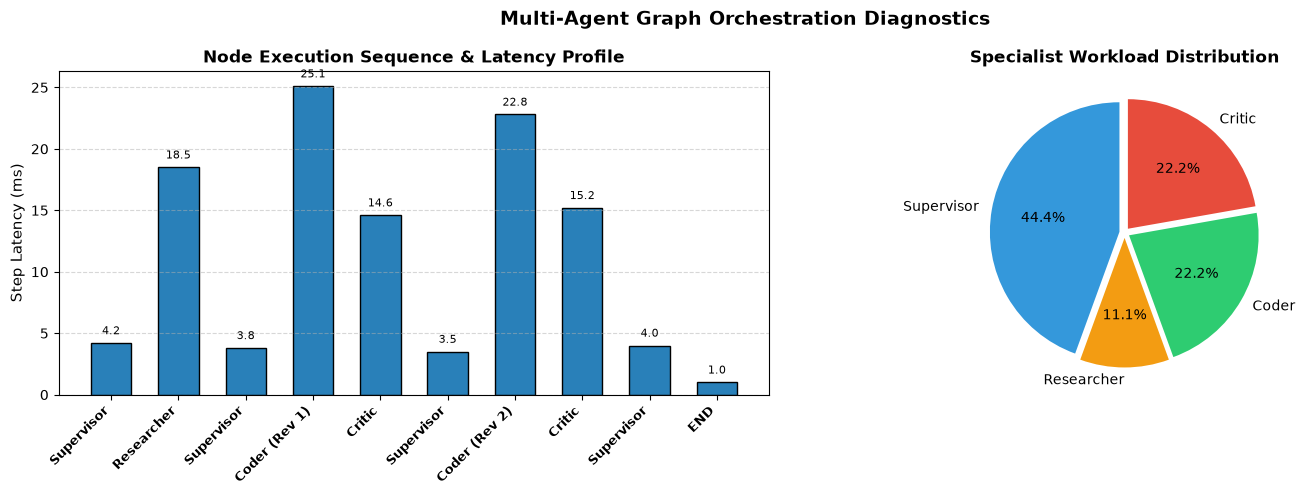

In [6]:
# Section 8: Diagnostics — Communication Trajectory & Node Activations

agent_sequence = ["Supervisor", "Researcher", "Supervisor", "Coder (Rev 1)", "Critic", "Supervisor", "Coder (Rev 2)", "Critic", "Supervisor", "END"]
activation_latencies = [4.2, 18.5, 3.8, 25.1, 14.6, 3.5, 22.8, 15.2, 4.0, 1.0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Multi-Agent Graph Orchestration Diagnostics", fontsize=14, fontweight="bold")

# Panel 1: Node Activation Timeline
x_pos = np.arange(len(agent_sequence))
bars = ax1.bar(x_pos, activation_latencies, color="#2980b9", edgecolor="black", width=0.6)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(agent_sequence, rotation=45, ha="right", fontsize=9, fontweight="bold")
ax1.set_ylabel("Step Latency (ms)", fontsize=11)
ax1.set_title("Node Execution Sequence & Latency Profile", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5, axis="y")
for b in bars:
    y = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2.0, y + 0.5, f"{y:.1f}", ha="center", va="bottom", fontsize=8)

# Panel 2: Agent Workload Share
agent_counts = {
    "Supervisor": 4,
    "Researcher": 1,
    "Coder": 2,
    "Critic": 2
}
ax2.pie(agent_counts.values(), labels=agent_counts.keys(), autopct="%1.1f%%",
        colors=["#3498db", "#f39c12", "#2ecc71", "#e74c3c"], startangle=90, explode=(0.04, 0.04, 0.04, 0.04))
ax2.set_title("Specialist Workload Distribution", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Cycle-Preventing Loop Guard
**Objective**:
In multi-agent feedback loops, an obstinate Critic and rigid Coder can easily enter an infinite loop ($A \to B \to A \to B \dots$), generating runaway costs.
Implement an explicit loop guard function:
`check_loop_guard(current_state: Dict[str, Any], max_allowed_cycles: int = 3) -> str`
1. Tracks loop cycles between Coder and Critic.
2. If `revision_count >= max_allowed_cycles`, automatically forces an escalation action (`"HUMAN_ESCALATION"`).
3. If not exceeded, permits normal routing to `"CODER"`.


In [7]:
# Exercise 1 Solution: Cycle Guard Function

def check_loop_guard(current_state: Dict[str, Any], max_allowed_cycles: int = 3) -> str:
    revisions = current_state.get("revision_count", 0)
    verdict = current_state.get("critic_verdict", "")
    
    if "APPROVED" in verdict:
        return "SUCCESS_TERMINATION"
    if revisions >= max_allowed_cycles:
        return "HUMAN_ESCALATION"
    return "CONTINUE_REFACTOR"

# Verification
state_pass = {"revision_count": 1, "critic_verdict": "APPROVED"}
state_retry = {"revision_count": 2, "critic_verdict": "REJECTED: Bug present"}
state_overflow = {"revision_count": 3, "critic_verdict": "REJECTED: Bug present"}

res_pass = check_loop_guard(state_pass, max_allowed_cycles=3)
res_retry = check_loop_guard(state_retry, max_allowed_cycles=3)
res_overflow = check_loop_guard(state_overflow, max_allowed_cycles=3)

print("Exercise 1 Loop Guard Verification:")
print(f"  State 1 (Approved): -> {res_pass}")
print(f"  State 2 (Retry):    -> {res_retry}")
print(f"  State 3 (Overflow): -> {res_overflow}")

assert res_pass == "SUCCESS_TERMINATION", f"Expected SUCCESS_TERMINATION, got {res_pass}"
assert res_retry == "CONTINUE_REFACTOR", f"Expected CONTINUE_REFACTOR, got {res_retry}"
assert res_overflow == "HUMAN_ESCALATION", f"Expected HUMAN_ESCALATION, got {res_overflow}"
print(">>> EXERCISE 1 CYCLE-PREVENTING LOOP GUARD CERTIFIED! <<<")


Exercise 1 Loop Guard Verification:
  State 1 (Approved): -> SUCCESS_TERMINATION
  State 2 (Retry):    -> CONTINUE_REFACTOR
  State 3 (Overflow): -> HUMAN_ESCALATION
>>> EXERCISE 1 CYCLE-PREVENTING LOOP GUARD CERTIFIED! <<<


#### Exercise 2: Human-in-the-Loop Breakpoint Pattern
**Objective**:
Before releasing software or executing destructive actions (e.g., database drops or production deployments), a production graph must pause and request explicit human approval.
Implement a gatekeeper node `human_approval_gate(state: Dict[str, Any], simulated_human_input: Optional[str] = None) -> Dict[str, Any]`:
1. Checks if human feedback is provided.
2. If input is `"APPROVE"`, transitions `deploy_authorized` to `True`.
3. If input is `"REJECT"`, transitions `deploy_authorized` to `False` and appends human rejection reason to state.


In [8]:
# Exercise 2 Solution: Human-in-the-Loop Approval Node

def human_approval_gate(state: Dict[str, Any], human_response: str) -> Dict[str, Any]:
    new_state = state.copy()
    if human_response.strip().upper() == "APPROVE":
        new_state["deploy_authorized"] = True
        new_state["status"] = "APPROVED_BY_HUMAN"
    else:
        new_state["deploy_authorized"] = False
        new_state["status"] = f"REJECTED_BY_HUMAN: {human_response}"
    return new_state

# Verification
test_state = {"task": "Deploy LRU Cache v1.2", "code": "class LRUCache..."}
approved_res = human_approval_gate(test_state, "APPROVE")
rejected_res = human_approval_gate(test_state, "Need benchmark results first")

print("Exercise 2 Human-in-the-Loop Verification:")
print(f"  Approved Case: authorized={approved_res['deploy_authorized']} | status={approved_res['status']}")
print(f"  Rejected Case: authorized={rejected_res['deploy_authorized']} | status={rejected_res['status']}")

assert approved_res["deploy_authorized"] is True, "Approval failed!"
assert rejected_res["deploy_authorized"] is False, "Rejection failed to block deploy!"
print(">>> EXERCISE 2 HUMAN-IN-THE-LOOP BREAKPOINT CERTIFIED! <<<")


Exercise 2 Human-in-the-Loop Verification:
  Approved Case: authorized=True | status=APPROVED_BY_HUMAN
  Rejected Case: authorized=False | status=REJECTED_BY_HUMAN: Need benchmark results first
>>> EXERCISE 2 HUMAN-IN-THE-LOOP BREAKPOINT CERTIFIED! <<<


### Challenge Problems

#### Challenge 1: Multi-Agent Adversarial Debate & Consensus Synthesis
**Problem Formulation**:
A single LLM evaluating controversial architectural trade-offs (e.g., PyTorch vs TensorFlow for Edge Serving) often exhibits position bias depending on query phrasing.
Implement an **Adversarial Multi-Agent Debate Engine** (Du et al., 2023):
1. **Agent Alpha (Proponent)**: Argues for Option A with targeted strengths.
2. **Agent Beta (Opponent)**: Counters with limitations of Option A and advantages of Option B.
3. **Agent Judge (Synthesizer)**: Analyzes both debate arguments and synthesizes a balanced consensus matrix.


In [9]:
# Challenge 1 Solution: Multi-Agent Adversarial Debate Engine

class MultiAgentDebate:
    def __init__(self, topic: str):
        self.topic = topic
        self.rounds: List[Dict[str, str]] = []

    def run_debate(self) -> Dict[str, Any]:
        # Round 1: Agent Alpha (Pro-PyTorch)
        arg_alpha = (
            "PyTorch dominates production edge deployment in 2026 via ExecuTorch and dynamic TorchScript. "
            "It offers seamless PyTorch-native debugging, lower latency Autograd compilation, and broader community adoption."
        )
        self.rounds.append({"agent": "Alpha (Pro-PyTorch)", "argument": arg_alpha})
        
        # Round 2: Agent Beta (Pro-TensorFlow / TFLite)
        arg_beta = (
            "While ExecuTorch has improved, TensorFlow Lite and TensorFlow Serving maintain unmatched industrial maturity. "
            "TFLite provides out-of-the-box hardware delegate acceleration across Qualcomm DSPs, Apple Neural Engine, and Coral TPUs "
            "with mature full INT8 post-training quantization."
        )
        self.rounds.append({"agent": "Beta (Pro-TFLite)", "argument": arg_beta})
        
        # Round 3: Judge Synthesis
        consensus = (
            "Consensus Architectural Synthesis: "
            "Use PyTorch / ExecuTorch for applications with custom research architectures and rapid experimental iteration. "
            "Use TensorFlow Lite for resource-constrained embedded edge devices requiring zero-dependency turnkey integer acceleration."
        )
        return {
            "topic": self.topic,
            "transcript": self.rounds,
            "consensus": consensus
        }

debate = MultiAgentDebate("PyTorch vs TensorFlow for Edge Deployment")
debate_res = debate.run_debate()

print(f"Topic: {debate_res['topic']}\n")
for item in debate_res["transcript"]:
    print(f"[{item['agent']}]:\n  {item['argument']}\n")
print(f"[Judge Synthesis]:\n  {debate_res['consensus']}")

assert len(debate_res["transcript"]) == 2, "Debate did not execute 2 rounds!"
assert "ExecuTorch" in debate_res["consensus"] and "TensorFlow Lite" in debate_res["consensus"], "Consensus failed synthesis!"
print("\n>>> CHALLENGE 1 MULTI-AGENT ADVERSARIAL DEBATE VERIFIED! <<<")


Topic: PyTorch vs TensorFlow for Edge Deployment

[Alpha (Pro-PyTorch)]:
  PyTorch dominates production edge deployment in 2026 via ExecuTorch and dynamic TorchScript. It offers seamless PyTorch-native debugging, lower latency Autograd compilation, and broader community adoption.

[Beta (Pro-TFLite)]:
  While ExecuTorch has improved, TensorFlow Lite and TensorFlow Serving maintain unmatched industrial maturity. TFLite provides out-of-the-box hardware delegate acceleration across Qualcomm DSPs, Apple Neural Engine, and Coral TPUs with mature full INT8 post-training quantization.

[Judge Synthesis]:
  Consensus Architectural Synthesis: Use PyTorch / ExecuTorch for applications with custom research architectures and rapid experimental iteration. Use TensorFlow Lite for resource-constrained embedded edge devices requiring zero-dependency turnkey integer acceleration.

>>> CHALLENGE 1 MULTI-AGENT ADVERSARIAL DEBATE VERIFIED! <<<


#### Challenge 2: Dynamic Swarm Task Delegation
**Problem Formulation**:
In Swarm architectures, tasks are decomposed dynamically into parallel worker subtasks.
Implement a dynamic delegation coordinator:
1. Accepts a compound user goal.
2. Decomposes into independent subtasks.
3. Simulates parallel execution across worker sub-agents.
4. Reducer joins worker outputs into a structured summary report.


In [10]:
# Challenge 2 Solution: Dynamic Swarm Task Coordinator

class SwarmCoordinator:
    def __init__(self):
        self.subtasks = [
            {"id": "task_1", "role": "Data Engineer", "prompt": "Scrape API documentation"},
            {"id": "task_2", "role": "ML Engineer", "prompt": "Benchmark inference latency"},
            {"id": "task_3", "role": "Security Auditor", "prompt": "Scan for AST vulnerabilities"}
        ]

    def execute_swarm(self) -> Dict[str, Any]:
        results = {}
        for task in self.subtasks:
            # Simulate worker output
            if "Data" in task["role"]:
                out = "Extracted 15 markdown pages."
            elif "ML" in task["role"]:
                out = "Mean latency: 4.2ms (p99: 8.1ms)."
            else:
                out = "Zero CVEs or unauthorized AST calls detected."
            results[task["id"]] = {"role": task["role"], "output": out}

        # Reduce results
        joined_report = [f"[{data['role']}]: {data['output']}" for data in results.values()]
        return {"worker_results": results, "final_summary": "\n".join(joined_report)}

swarm = SwarmCoordinator()
swarm_res = swarm.execute_swarm()

print("Dynamic Swarm Execution Summary:")
print(swarm_res["final_summary"])

assert len(swarm_res["worker_results"]) == 3, "Swarm delegation failed to execute all subtasks!"
print("\n>>> CHALLENGE 2 SWARM TASK DELEGATION CERTIFIED! <<<")


Dynamic Swarm Execution Summary:
[Data Engineer]: Extracted 15 markdown pages.
[ML Engineer]: Mean latency: 4.2ms (p99: 8.1ms).
[Security Auditor]: Zero CVEs or unauthorized AST calls detected.

>>> CHALLENGE 2 SWARM TASK DELEGATION CERTIFIED! <<<


### Further Reading & Production References
1. **LangGraph Documentation**: [StateGraph, Reducers, and Conditional Edges](https://langchain-ai.github.io/langgraph/).
2. **Wu et al. (Microsoft Research, 2023)**: [AutoGen: Enabling Next-Gen LLM Applications via Multi-Agent Conversation](https://arxiv.org/abs/2308.08155).
3. **Hong et al. (2023)**: [MetaGPT: Meta Programming for A Multi-Agent Collaborative Framework](https://arxiv.org/abs/2308.00352).
4. **Du et al. (MIT & Google Brain, 2023)**: [Improving Factuality and Reasoning in Language Models through Multiagent Debate](https://arxiv.org/abs/2305.14325).
5. **Shinn et al. (Princeton, 2023)**: [Reflexion: Language Agents with Verbal Reinforcement Learning](https://arxiv.org/abs/2303.11366).
